> **⚠ Review note (added during project reorganisation, not by the original author)**
> 1. `target_congestion` is a deterministic function of `target_next_count / road_capacity` (Low < 0.35 ≤ Moderate < 0.60 ≤ High < 0.85 ≤ Severe). In this notebook `target_next_count` is left in `X`, so the models can read the answer off one column. The 99%+ accuracies below are therefore **inflated by target leakage** and should not be quoted as real forecasting accuracy. Drop `target_next_count` (as `src/components/data_transformation.py` already does).
> 2. The split is a random stratified split. For time-series data, use a chronological split (train on the past, test on the future).
> 3. 4 rows have a missing label; `LabelEncoder` turns them into a 5th class (`nan`). Drop them before encoding.
> 4. The confusion-matrix tick labels say `Very High`; the dataset's class is `Severe`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,classification_report, confusion_matrix   

df = pd.read_csv("../../data/processed/team_alt_cleaning/setup_team_imputed_cleaned.csv")

df.head()

,timestamp,intersection_id,hour,minute,day_of_week,is_weekend,is_holiday,event_nearby,temperature_c,rain_mm_15min,...,avg_waiting_time_sec,queue_length_veh,incident_flag,prev_count_15min,prev_count_1h,count_same_time_yesterday,count_same_time_last_week,rolling_mean_1h,target_next_count,target_congestion
0,2025-01-06 00:00:00,INT_01_CBD,0,0,0,0,0,0,2.6,0.0,...,11.5,1.5,0,85.0,85.0,85.0,85.0,86.25,36.0,Low
1,2025-01-06 00:15:00,INT_01_CBD,0,15,0,0,0,0,2.7,0.0,...,3.4,0.3,0,23.0,85.0,85.0,85.0,86.25,28.0,Low
2,2025-01-06 00:30:00,INT_01_CBD,0,30,0,0,0,0,2.4,0.0,...,11.3,0.0,0,36.0,85.0,85.0,85.0,86.25,33.0,Low
3,2025-01-06 00:45:00,INT_01_CBD,0,45,0,0,0,0,1.5,0.0,...,5.8,0.4,0,28.0,85.0,85.0,85.0,86.25,19.0,Low
4,2025-01-06 01:00:00,INT_01_CBD,1,0,0,0,0,0,3.1,0.0,...,0.0,0.0,0,33.0,23.0,85.0,85.0,30.00,32.0,Low


In [2]:
X = df.drop('target_congestion', axis=1)
y = df['target_congestion']

In [3]:
X = X.drop('timestamp', axis=1)

In [4]:
X = pd.get_dummies(
    X,
    columns=['intersection_id'],
    drop_first=True
)

In [5]:
encoder = LabelEncoder()

y = encoder.fit_transform(y)

print(encoder.classes_)

['High' 'Low' 'Moderate' 'Severe' nan]


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)

lr_pred = lr.predict(X_test_scaled)

print("Logistic Regression:",
      accuracy_score(y_test, lr_pred))

Logistic Regression: 0.9914641203703703


In [9]:
svc = SVC(kernel='linear')
svc.fit(X_train_scaled, y_train)

svc_pred = svc.predict(X_test_scaled)

print("SVC:",
      accuracy_score(y_test, svc_pred))

SVC: 0.9963107638888888


In [10]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

knn_pred = knn.predict(X_test_scaled)

print("KNN:",
      accuracy_score(y_test, knn_pred))

KNN: 0.9152922453703703


In [11]:
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("Random Forest:",
      accuracy_score(y_test, rf_pred))

Random Forest: 0.9971788194444444


In [12]:
# Store all model accuracies

lr_accuracy = accuracy_score(y_test, lr_pred)
svc_accuracy = accuracy_score(y_test, svc_pred)
knn_accuracy = accuracy_score(y_test, knn_pred)
rf_accuracy = accuracy_score(y_test, rf_pred)

results = {
    "Logistic Regression": lr_accuracy,
    "SVC": svc_accuracy,
    "KNN": knn_accuracy,
    "Random Forest": rf_accuracy
}

for model_name, accuracy in results.items():
    print(f"{model_name}: {accuracy:.4f}")

Logistic Regression: 0.9915
SVC: 0.9963
KNN: 0.9153
Random Forest: 0.9972


In [13]:
best_model_name = max(
    results,
    key=results.get
)

best_accuracy = results[best_model_name]

print("Best Model:", best_model_name)
print("Best Accuracy: {:.2f}%".format(
    best_accuracy * 100
))

Best Model: Random Forest
Best Accuracy: 99.72%


In [14]:
from sklearn.metrics import classification_report

print("Classification Report")
print("=====================")
print("Best Model:", best_model_name)
print()

print(
    classification_report(
        y_test,
        best_predictions
    )
)

Classification Report
Best Model: Random Forest



NameError: name 'best_predictions' is not defined

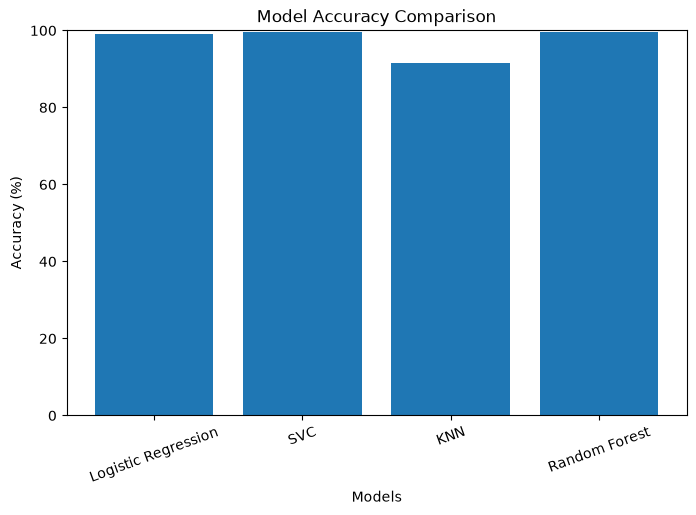

In [ ]:
plt.figure(figsize=(8, 5))

models = list(results.keys())
accuracies = [value * 100 for value in results.values()]

plt.bar(models, accuracies)

plt.xlabel("Models")
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison")

plt.ylim(0, 100)
plt.xticks(rotation=20)

plt.show()

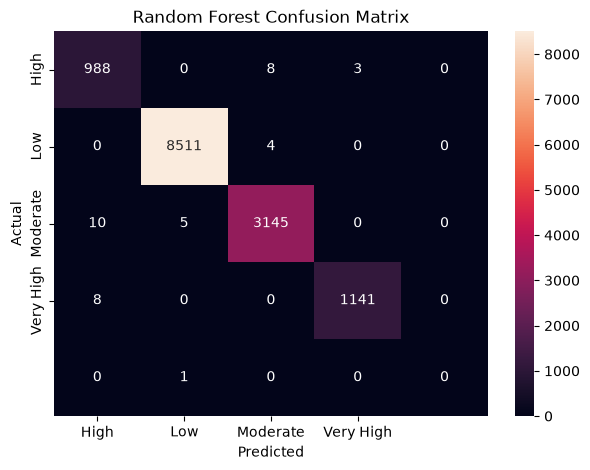

In [ ]:
cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["High", "Low", "Moderate", "Very High"],
    yticklabels=["High", "Low", "Moderate", "Very High"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

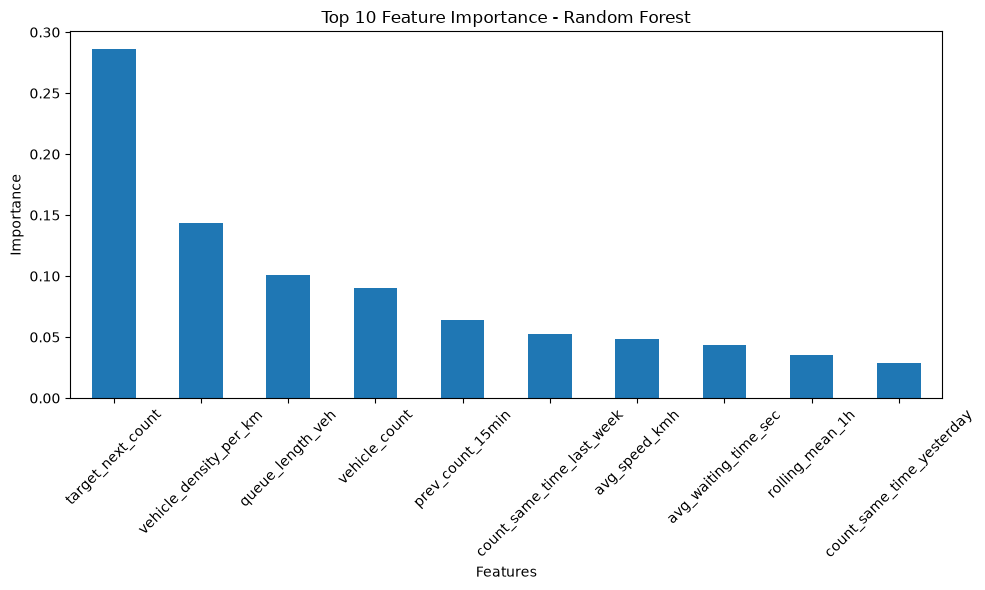

In [ ]:
feature_importance = pd.Series(
    rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))

feature_importance.head(10).plot(kind="bar")

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Top 10 Feature Importance - Random Forest")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()